# AgriStress-500 Plant→Image Pipeline

Download the dataset -> sample parent field images and their cropped plant instances -> generate embeddings via the PAI embedding API -> run Plant-to-Image evaluation, using the `precisionai.agriemb` package that wires the three sibling projects together:

- [Precision AI Embeddings](https://embeddings.precision.ai/) - hosted image embedding API
- [`agrieval`](https://github.com/Precision-AI-Inc/agrieval) - embedding evaluation
- [`agristress-utils`](https://github.com/Precision-AI-Inc/agristress-utils) - dataset download and sampling

Plant→Image measures how well a parent field image's embedding retrieves its own cropped plant instances, and vice versa.

**Setup** (from the repo root, before starting Jupyter):

```bash
pip install -e ".[notebook]"
cp .env.example .env   # fill in PAI_EMBEDDINGS_BASE_URL and PAI_EMBEDDINGS_API_KEY
```

Run all cells top-to-bottom. See the root `README.md` and the standalone `examples/01_download_dataset.py` plus `examples/plant2image/01_sample_cluster_instances.py`-`03_run_eval.py` (or the bundled `04_end_to_end.py`) scripts for the non-notebook version.

In [ ]:
from IPython.display import display
from PIL import Image

from precisionai.agriemb import build_client, download, embed_images, run_p2i_evaluation, sample_cluster_instances
from precisionai.agriemb.config import DEFAULT_DATASET_DIR, DEFAULT_MODEL, DEFAULT_REPO_ID
from precisionai.agrieval.emb import plot_cosine_similarity, plot_knn_confusion, plot_tsne, print_result
from precisionai.agristress.utils import AgriStressDataset, normalize_embeddings, validate_embeddings

SEED = 0
NUM_SAMPLES = 3
MAX_INSTANCES_PER_IMAGE = 4

## 1. Download the dataset

In [ ]:
dataset_dir = download(DEFAULT_DATASET_DIR, repo_id=DEFAULT_REPO_ID)
dataset = AgriStressDataset(dataset_dir)
clusters = dataset.list_clusters()

print(f"Downloaded to {dataset_dir}")
print(f"Clusters : {len(clusters)}")
print(f"Images   : {len(dataset.list_image_ids())}")

## 2. Sample parent images and their instance crops

Picks a random L2 cluster, draws `NUM_SAMPLES` parent images from it, and collects up to `MAX_INSTANCES_PER_IMAGE` cropped plant instances per parent. Pass `cluster="A1"` (or any id from `clusters` above) to target a specific one.

In [3]:
cluster, images, instances = sample_cluster_instances(
    dataset,
    cluster="A1",
    num_samples=NUM_SAMPLES,
    max_instances_per_image=MAX_INSTANCES_PER_IMAGE,
    seed=SEED,
)
sample = images + instances
paths = dataset.resolve_paths(sample)

print(f"Cluster {cluster}: sampled {len(images)} parent images and {len(instances)} instance crops")

Cluster A1: sampled 3 parent images and 12 instance crops


### Preview the parent images

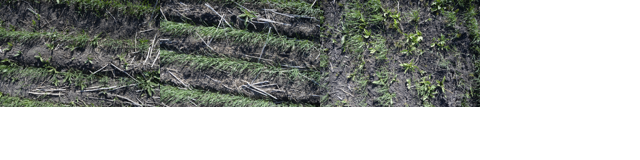

images/A1/pai-SbcQ1Av0.png
images/A1/pai-fMEceubf.png
images/A1/pai-Ooz3Qfkt.png


In [4]:
thumb_size = 160
cols = 4
rows = (len(images) + cols - 1) // cols

sheet = Image.new("RGB", (cols * thumb_size, rows * thumb_size), "white")
for i, image_id in enumerate(images):
    thumb = Image.open(paths[image_id]).convert("RGB")
    thumb.thumbnail((thumb_size, thumb_size))
    x, y = (i % cols) * thumb_size, (i // cols) * thumb_size
    sheet.paste(thumb, (x, y))

display(sheet)
print("\n".join(images))

### Preview the instance crops

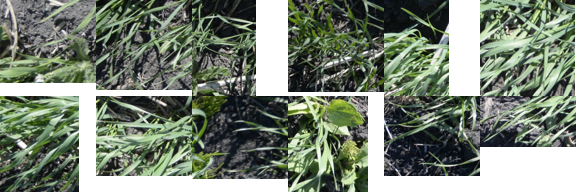

instances/A1/pai-SbcQ1Av0-16.png
instances/A1/pai-SbcQ1Av0-9.png
instances/A1/pai-SbcQ1Av0-15.png
instances/A1/pai-SbcQ1Av0-1.png
instances/A1/pai-fMEceubf-9.png
instances/A1/pai-fMEceubf-16.png
instances/A1/pai-fMEceubf-8.png
instances/A1/pai-fMEceubf-7.png
instances/A1/pai-Ooz3Qfkt-10.png
instances/A1/pai-Ooz3Qfkt-8.png
instances/A1/pai-Ooz3Qfkt-6.png
instances/A1/pai-Ooz3Qfkt-16.png


In [5]:
thumb_size = 96
cols = 6
rows = (len(instances) + cols - 1) // cols

sheet = Image.new("RGB", (cols * thumb_size, rows * thumb_size), "white")
for i, instance_id in enumerate(instances):
    thumb = Image.open(paths[instance_id]).convert("RGB")
    thumb.thumbnail((thumb_size, thumb_size))
    x, y = (i % cols) * thumb_size, (i // cols) * thumb_size
    sheet.paste(thumb, (x, y))

display(sheet)
print("\n".join(instances))

## 3. Generate embeddings via the PAI embedding API

Each sampled parent image and instance crop is base64-encoded as a `data:` URI and sent to the OpenAI-compatible PAI embedding API (https://embeddings.precision.ai/), then L2-normalized and validated.

In [6]:
client = build_client()
raw_embeddings = embed_images(client, paths, model=DEFAULT_MODEL)

embeddings = normalize_embeddings(raw_embeddings)
validate_embeddings(embeddings)

print(f"Generated {len(embeddings)} L2-normalized embeddings (dim={len(next(iter(embeddings.values())))})")

Generated 15 L2-normalized embeddings (dim=384)


## 4. Run Plant-to-Image evaluation

`run_p2i_evaluation` assembles the parent-image-to-instance-crop groups from `plant2image.json` (via `AgriStressDataset.build_p2i_payload`) and evaluates them with `agrieval`'s `run_plant2image_eval` for graded nDCG and per-parent-image group analysis.

In [7]:
result = run_p2i_evaluation(dataset, embeddings, k_values=[5, 10])
print_result(result)

n_items      : 15
embedding_dim: 384
classes      : ['A']
k_values     : [5, 10]

── global_metrics ──────────────────────────────────────────────────────
  pairwise cosine    : mean=0.9283  std=0.0545  (p05=0.7780  p50=0.9459  p95=0.9767)
  centroid cosine    : mean=0.9660  std=0.0327  norm=0.9660
  effective_rank     : 4.10  (ratio=0.0107  dim=384)
  uniformity         : -0.2663
  alignment          : 0.1233

  hubness@5         : mean=5.0000  std=3.0111  p95=8.8000
  hubness@10        : mean=10.0000  std=3.9665  p95=14.0000
  knn_radius@5         : mean=0.9477  std=0.0302  p05=0.9128  p95=0.9623
  knn_radius@10        : mean=0.9264  std=0.0421  p05=0.8726  p95=0.9491
  mean_top_k_sim@5         : mean=0.9568  std=0.0263  p05=0.9260  p95=0.9710
  mean_top_k_sim@10        : mean=0.9449  std=0.0329  p05=0.9046  p95=0.9607
  outlier_score@5         : mean=0.0432  std=0.0263  p95=0.0740
  outlier_score@10        : mean=0.0551  std=0.0329  p95=0.0954

  P@K (meta)@5         : mean=0.3600  

## 5. Visualize (optional)

Requires `precisionai-agrieval[analysis]` (already included in the `notebook` extra). `output_path=None` renders the interactive Plotly figure inline instead of saving an HTML file.

In [8]:
plot_cosine_similarity(embeddings, result, output_path=None)

In [9]:
plot_tsne(embeddings, result, output_path=None, dimensions=2)

  t-SNE 2D — fitting 15 samples (perplexity=5, iter=1000)...


In [10]:
plot_knn_confusion(result, k=5, output_path=None)